# Moving average crossover: walkthrough

A short tour of the results. All logic lives in `src/`; this notebook only calls it.

**Strategy:** hold SPY while its 50-day simple moving average is above its 200-day average, otherwise hold cash. The signal is computed at the close, and the position starts the **next** day.

**Question:** does this beat simply buying and holding SPY, after costs and on data it was not tuned on?

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable from notebooks/

import pandas as pd

from src.backtest import out_of_sample_test, parameter_sweep, run_backtest
from src.data import load_prices
from src.metrics import format_table, summary_table
from src.plots import plot_drawdown, plot_equity, plot_sharpe_heatmap
from src.strategy import generate_signals

TICKER, SHORT, LONG, COST = "SPY", 50, 200, 0.001
SHORTS, LONGS = list(range(10, 101, 10)), list(range(50, 301, 25))

## 1. Data
Daily adjusted close prices (splits and dividends included), cached in `data/`.

In [2]:
prices = load_prices(TICKER, "2005-01-01")
print(f"{len(prices):,} trading days, {prices.index[0].date()} -> {prices.index[-1].date()}")
prices.tail(3)

5,509 trading days, 2005-01-03 -> 2026-11-24


date
2026-11-20    689.809998
2026-11-23    722.289978
2026-11-24    718.780029
Name: close, dtype: float64

## 2. Signals and look-ahead bias
`signal` uses today's close, so `position` (what we hold) is yesterday's signal. To see why that matters, compare total returns with the shift and without it. The unshifted version earns each day's return using a signal that already knows that day's close.

In [3]:
rows = {}
for short, long in [(50, 200), (10, 30), (2, 5)]:
    df = generate_signals(prices, short, long)
    r = df["close"].pct_change().fillna(0)
    rows[f"SMA {short}/{long}"] = {
        "Honest (shifted)": (1 + df["position"] * r).prod() - 1,
        "Look-ahead (unshifted)": (1 + df["signal"] * r).prod() - 1,
    }
pd.DataFrame(rows).T.map("{:,.0%}".format)

,Honest (shifted),Look-ahead (unshifted)
SMA 50/200,516%,546%
SMA 10/30,264%,714%
SMA 2/5,40%,"908,857%"


The faster the signal, the bigger the fake profit. A backtest without this shift isn't just a bit optimistic, it's wrong.

## 3. Backtest and metrics
Both curves start on the first day the 200-day average exists, with 10,000 and a 0.1% cost per trade.

In [4]:
bt = run_backtest(generate_signals(prices, SHORT, LONG), cost=COST)
format_table(summary_table(bt))

,Strategy,Buy & Hold
Total return,503.1%,784.8%
CAGR,8.9%,10.9%
Annualized volatility,13.9%,19.2%
Sharpe ratio,0.68,0.64
Max drawdown,-33.7%,-55.2%
Number of trades,21,1
Time in market,79.2%,100.0%


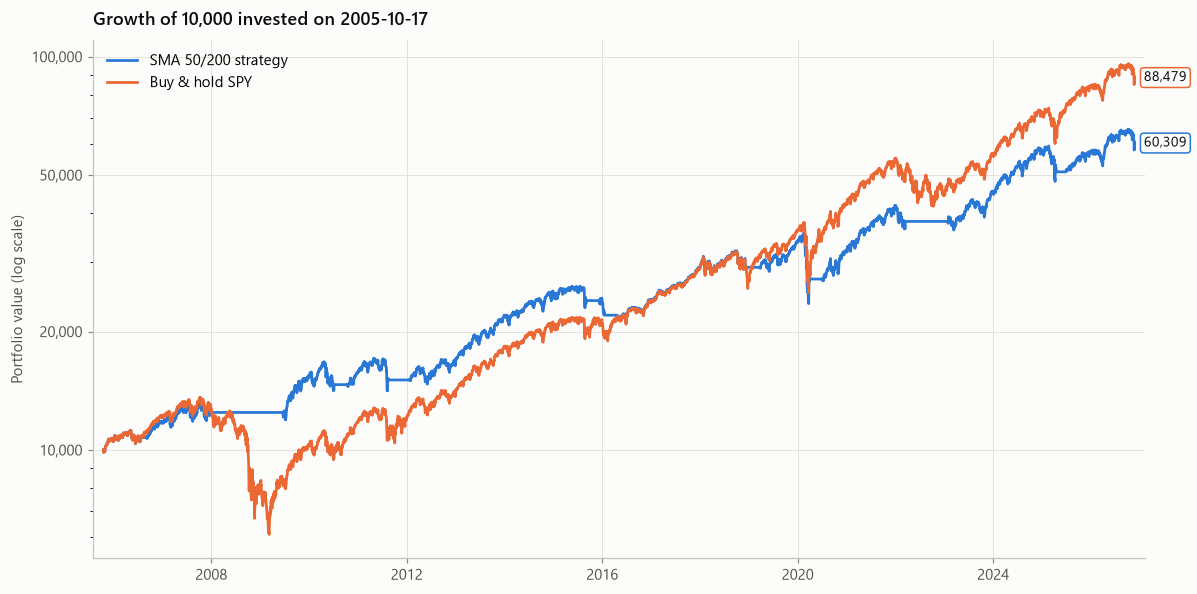

In [5]:
_ = plot_equity(bt, TICKER, SHORT, LONG)

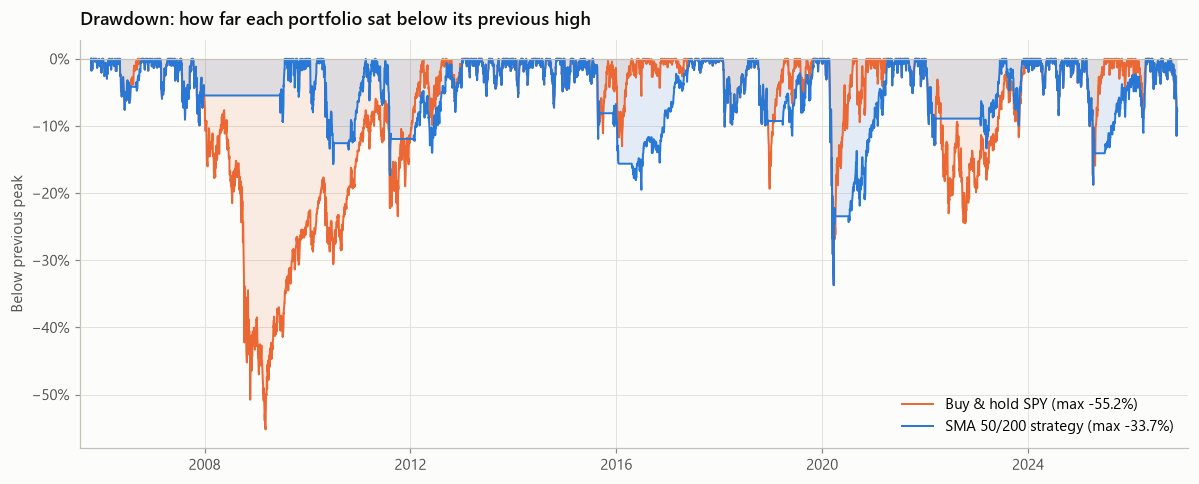

In [6]:
_ = plot_drawdown(bt, TICKER, SHORT, LONG)

Lower return, much lower drawdown. The strategy sat out most of 2008-09, but the 2020 crash was too fast for a 200-day average: the sell signal came after the bottom.

## 4. Parameter sweep
Sharpe ratio for 110 window pairs, all scored over the same dates. Blue beats buy-and-hold, red loses to it.

61 of 110 pairs beat buy & hold (Sharpe 0.62)


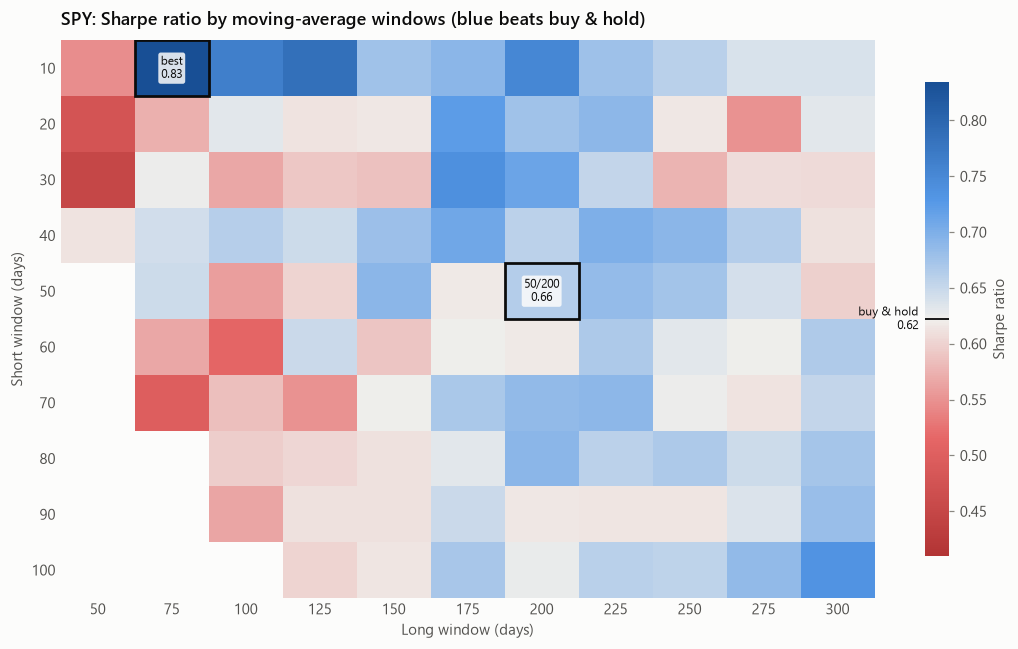

In [7]:
grid, buyhold_sharpe = parameter_sweep(prices, SHORTS, LONGS, cost=COST)
values = grid.stack()
print(f"{(values > buyhold_sharpe).sum()} of {values.size} pairs beat buy & hold (Sharpe {buyhold_sharpe:.2f})")
_ = plot_sharpe_heatmap(grid, buyhold_sharpe, TICKER)

The landscape is patchy: the best cell (10/75) sits next to much weaker neighbours. Picking it is fitting noise. With 110 tries, the luckiest one is bound to look good.

## 5. Out-of-sample test
Choose the best pair on 2005-2017 only, then evaluate it on 2018 onward.

In [8]:
oos = out_of_sample_test(prices, "2018-01-01", SHORTS, LONGS, cost=COST)
print("Chosen in-sample:", oos["best_pair"], "| out-of-sample rank:", oos["test_rank"], "of", oos["n_pairs"])
format_table(oos["out_of_sample"])

Chosen in-sample: (10, 75) | out-of-sample rank: 4 of 110


,Best in-sample 10/75,SMA 50/200,Buy & Hold
Total return,121.8%,106.7%,205.1%
CAGR,9.4%,8.5%,13.4%
Annualized volatility,12.1%,16.2%,19.1%
Sharpe ratio,0.80,0.59,0.75
Max drawdown,-21.1%,-33.7%,-33.7%
Number of trades,40,9,1
Time in market,76.4%,82.0%,100.0%


### Does that depend on the split date?
One split is one draw. Repeat it for several split dates:

In [9]:
rows = []
for split in ["2012-01-01", "2014-01-01", "2016-01-01", "2018-01-01", "2020-01-01", "2022-01-01"]:
    r = out_of_sample_test(prices, split, SHORTS, LONGS, cost=COST)
    s_in, s_out = r["in_sample"].loc["Sharpe ratio"], r["out_of_sample"].loc["Sharpe ratio"]
    rows.append({
        "split": split[:4],
        "chosen pair": f"{r['best_pair'][0]}/{r['best_pair'][1]}",
        "Sharpe in-sample": s_in.iloc[0],
        "Sharpe out-of-sample": s_out.iloc[0],
        "out-of-sample rank": f"{r['test_rank']}/{r['n_pairs']}",
        "50/200 out-of-sample": s_out.iloc[1],
        "Buy & hold out-of-sample": s_out.iloc[2],
    })
robustness = pd.DataFrame(rows).set_index("split")
robustness.round(2)

,chosen pair,Sharpe in-sample,Sharpe out-of-sample,out-of-sample rank,50/200 out-of-sample,Buy & hold out-of-sample
split,,,,,,
2012,10/75,0.66,0.90,3/110,0.72,0.89
2014,40/150,0.92,0.56,88/110,0.61,0.80
2016,30/175,0.77,0.72,21/110,0.65,0.84
2018,10/75,0.86,0.80,4/110,0.59,0.75
2020,30/175,0.85,0.58,56/110,0.57,0.74
2022,10/75,0.90,0.59,58/110,0.61,0.64


## 6. Conclusions

- The 2018 split you'd naturally pick happens to flatter the tuned pair. Across six split dates, buy-and-hold had the higher out-of-sample Sharpe in most of them.
- The tuned pair usually loses Sharpe out of sample. That is overfitting showing up as expected.
- Sharpe differences of 0.05-0.1 are noise over 10-20 years of data (standard error roughly 1/sqrt(years)).
- What does hold up: lower volatility and smaller drawdowns. On SPY, a moving average crossover is a risk-reduction tool, not a way to beat the market.

See the README for limitations.